In [2]:
%pip install statsmodels

Note: you may need to restart the kernel to use updated packages.


# 1. Importing Libraries & create Setup

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Project paths
DATA_DIR = Path("../data/raw/m5")
PROCESSED_DIR = Path("../data/processed")

SALES_PATH = DATA_DIR / "sales_train_validation.csv"
CALENDAR_PATH = PROCESSED_DIR / "calendar_cleaned.csv"

# Load calendar
calendar = pd.read_csv(CALENDAR_PATH, parse_dates=["date"])

print("Time Series Analysis Environment Ready!")
print("Calendar Shape:", calendar.shape)
print("Sales File Exists:", SALES_PATH.exists())
print("Date Range:", calendar["date"].min(), "to", calendar["date"].max())

Time Series Analysis Environment Ready!
Calendar Shape: (1969, 14)
Sales File Exists: True
Date Range: 2011-01-29 00:00:00 to 2016-06-19 00:00:00


# 2. Prepared Daily Sales Time Series

We'll get the daily sales time series of the business

In [4]:
daily_columns = [
    col for col in pd.read_csv(SALES_PATH, nrows=0).columns
    if col.startswith("d_")
]

daily_sales = np.zeros(
    len(daily_columns),
    dtype=np.int64
)

for chunk in pd.read_csv(SALES_PATH, chunksize=500):

    daily_sales += (
        chunk[daily_columns]
        .sum()
        .to_numpy(dtype=np.int64)
    )

daily_ts = pd.DataFrame({
    "date": calendar.set_index("d").loc[
        daily_columns, "date"
    ].values,
    "sales": daily_sales
})

daily_ts = daily_ts.sort_values("date")
daily_ts = daily_ts.set_index("date")

print("Time Series Shape:", daily_ts.shape)
display(daily_ts.head())

Time Series Shape: (1913, 1)


,sales
date,
2011-01-29,32631
2011-01-30,31749
2011-01-31,23783
2011-02-01,25412
2011-02-02,19146


# 3. Visualizing Daily Sales Trend

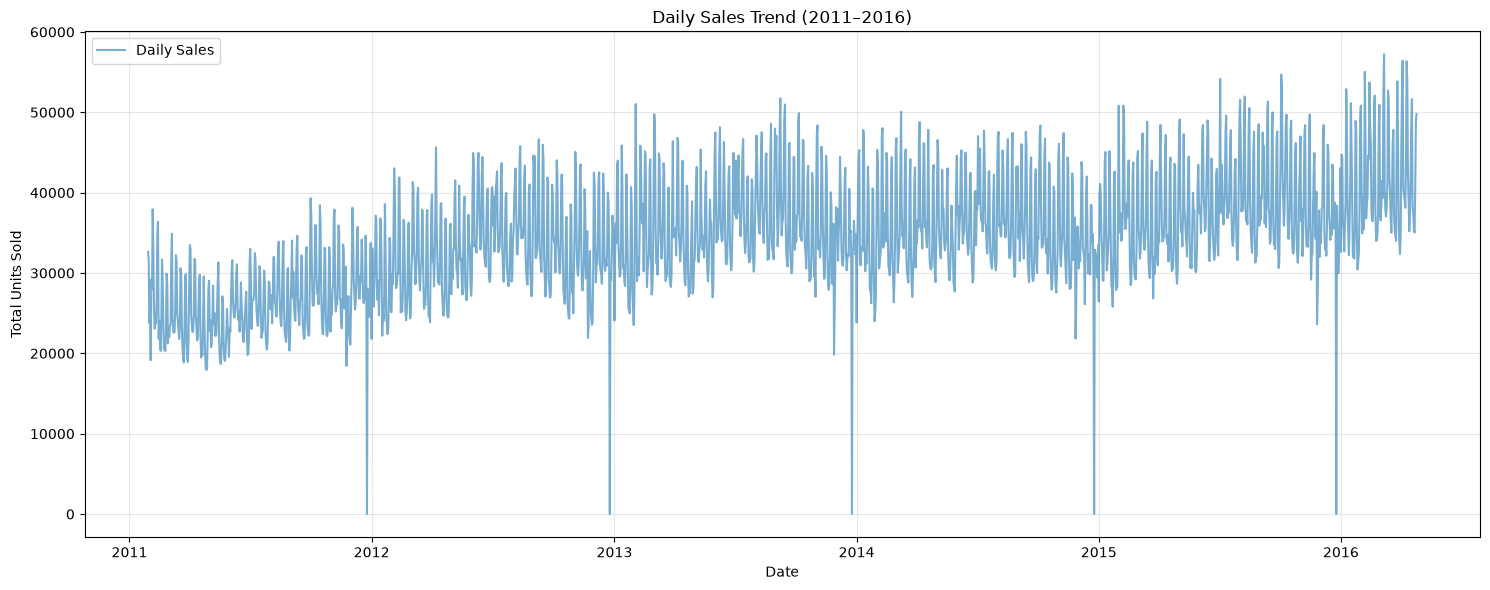

In [5]:
plt.figure(figsize=(15, 6))

plt.plot(
    daily_ts.index,
    daily_ts["sales"],
    label="Daily Sales",
    alpha=0.6
)

plt.title("Daily Sales Trend (2011–2016)")
plt.xlabel("Date")
plt.ylabel("Total Units Sold")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Graph Interpretation--
We can identify four important patterns:
1. Upward Trend: Overall daily sales increase from around 25,000 units in 2011 to around 40,000–45,000 units in 2016.
2. Frequent Fluctuations: Sales repeatedly rise and fall, indicating a strong weekly pattern.
3. Yearly Growth: Sales levels generally increase over the years, although growth isn't perfectly consistent.
4. Sudden Drops: There are sharp drops around Christmas each year. These may reflect store closures or reduced trading activity.
Project observation: The series shows an overall upward trend, recurring short-term fluctuations and possible yearly seasonal patterns.

# 4. Calculate Rolling Mean and Standard Deviation

Rolling statistics help us understand how sales behaviour changes over time.

In [6]:
print("Rolling Mean Summary:")
display(daily_ts["rolling_mean"].describe())

print("\nRolling Standard Deviation Summary:")
display(daily_ts["rolling_std"].describe())

print("\nFirst 5 Rolling Values:")
display(daily_ts[["sales", "rolling_mean", "rolling_std"]].head(35).tail(5))

Rolling Mean Summary:


KeyError: 'rolling_mean'

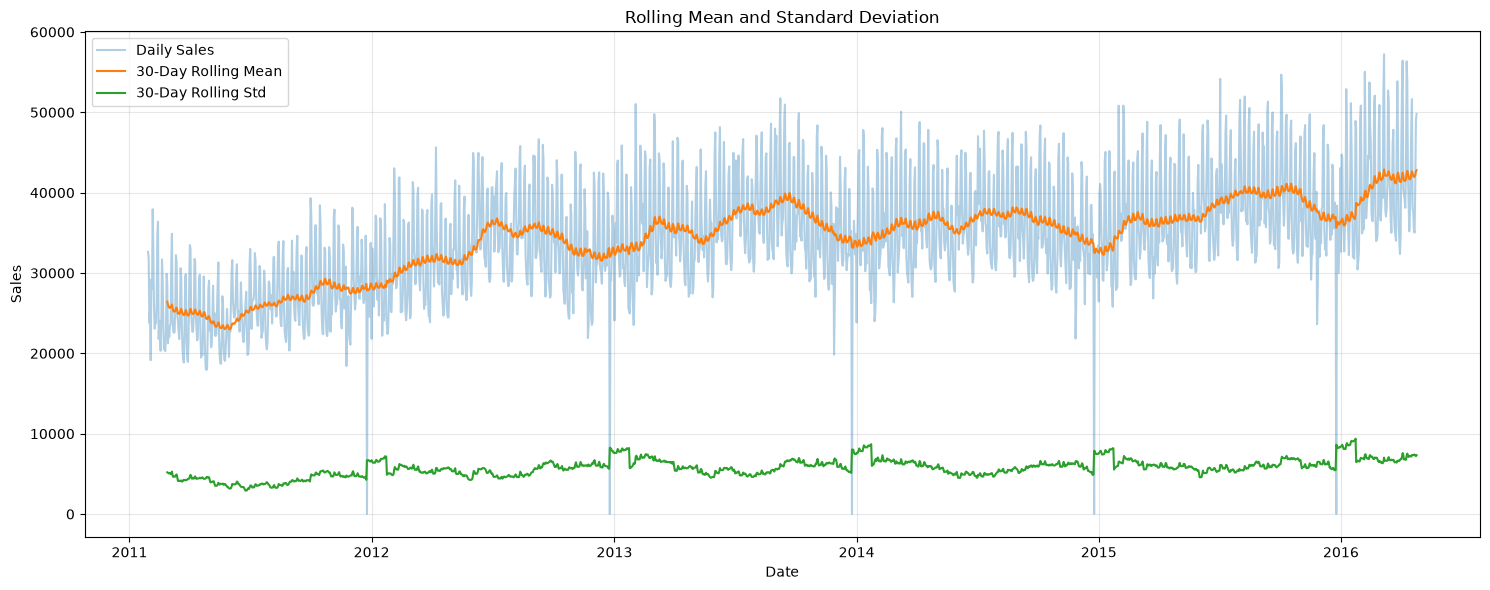

In [7]:
daily_ts["rolling_mean"] = (
    daily_ts["sales"].rolling(window=30).mean()
)

daily_ts["rolling_std"] = (
    daily_ts["sales"].rolling(window=30).std()
)

plt.figure(figsize=(15, 6))

plt.plot(
    daily_ts["sales"],
    label="Daily Sales",
    alpha=0.35
)

plt.plot(
    daily_ts["rolling_mean"],
    label="30-Day Rolling Mean"
)

plt.plot(
    daily_ts["rolling_std"],
    label="30-Day Rolling Std"
)

plt.title("Rolling Mean and Standard Deviation")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Observations: Rolling Mean and Standard Deviation

1. The 30-day rolling mean has an average value of approximately 34,331 units.
2. The rolling mean ranges from 22,981 to 42,888 units, indicating changes in the overall sales level over time.
3. The rolling standard deviation has an average value of approximately 5,743 units.
4. The variation in rolling standard deviation indicates that daily sales fluctuations are not constant.
5. Both rolling statistics show changes over time, suggesting that the sales time series may be non-stationary.

**Conclusion:** The changing rolling mean and standard deviation indicate that the dataset may not be stationary. Further statistical testing using the ADF test will help confirm this.

# 5. Seasonal Decomposition
Now we'll separate the sales time series into four components:
- Trend
- Seasonality
- Residuals
- Original observed sales
We'll first examine weekly seasonality using a period of 7 days

We'll first examine weekly seasonality using a period of 7 days.

In [20]:
print("Trend Summary:")
display(decomposition.trend.describe())

print("\nSeasonal Component Summary:")
display(decomposition.seasonal.describe())

print("\nResidual Summary:")
display(decomposition.resid.describe())

Trend Summary:


count     1907.000000
mean     34336.314181
std       4929.721957
min      21292.142857
25%      31371.000000
50%      35183.571429
75%      37842.214286
max      44982.285714
Name: trend, dtype: float64


Seasonal Component Summary:


count    1913.000000
mean        7.322115
std      4661.712421
min     -4324.895806
25%     -4139.353682
50%     -1459.929127
75%      6789.470558
max      7217.734738
Name: seasonal, dtype: float64


Residual Summary:


count     1907.000000
mean         0.546774
std       2663.686043
min     -31101.184843
25%      -1172.986659
50%        -86.707953
75%       1107.240052
max      13020.434904
Name: resid, dtype: float64

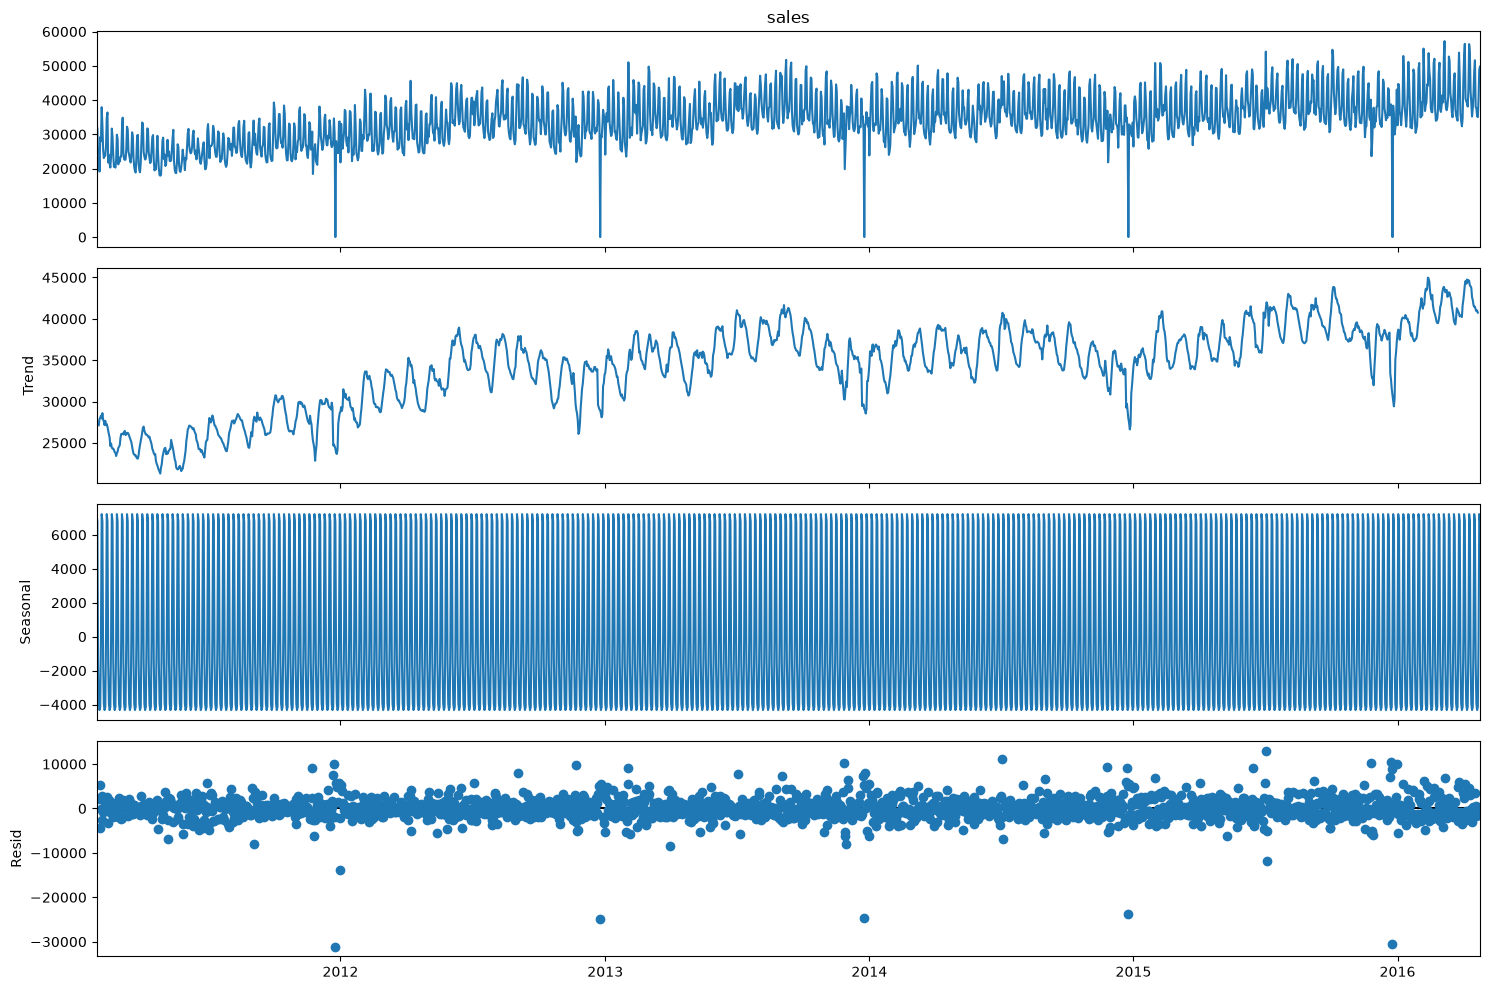

In [9]:
decomposition = seasonal_decompose(
    daily_ts["sales"],
    model="additive",
    period=7
)

fig = decomposition.plot()
fig.set_size_inches(15, 10)

plt.tight_layout()
plt.show()


### Observations: Seasonal Decomposition

1. **Trend:** The average trend is approximately 34,336 units, showing the overall movement in sales over time.
2. **Seasonality:** The seasonal component has a standard deviation of approximately 4,662 units, indicating noticeable weekly sales patterns.
3. **Residuals:** The residual component has a mean close to zero (0.55), suggesting that the decomposition has separated the main trend and seasonal patterns effectively.
4. **Sales Fluctuations:** The residual standard deviation is approximately 2,664 units, indicating variations that are not explained by the trend and weekly seasonality.

**Conclusion:** The sales data contains a noticeable upward trend and recurring weekly seasonality. Some unexplained fluctuations remain in the residual component.

# 6. Augmented Dickey-Fuller (ADF) Test
Now comes an important statistical test: Stationarity Testing.

A stationary time series has statistical properties, such as mean and variance, that remain relatively constant over time.

We'll use the ADF test to check whether our sales data is stationary.

In [10]:
adf_result = adfuller(daily_ts["sales"])

print("ADF Test Results")
print("-------------------------")
print("ADF Statistic:", adf_result[0])
print("p-value:", adf_result[1])
print("Critical Values:")

for key, value in adf_result[4].items():
    print(f"{key}: {value}")

if adf_result[1] <= 0.05:
    print("\nConclusion: The series is Stationary.")
else:
    print("\nConclusion: The series is Non-Stationary.")

ADF Test Results
-------------------------
ADF Statistic: -1.5653733253318467
p-value: 0.5009604361797744
Critical Values:
1%: -3.433822016251123
5%: -2.8630736989499335
10%: -2.567586484303047

Conclusion: The series is Non-Stationary.


/tmp/ipykernel_34359/806627296.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(daily_ts["sales"])


### Observations: Augmented Dickey-Fuller (ADF) Test

1. The ADF Statistic is -1.5654.
2. The p-value is 0.5010, which is greater than the significance level of 0.05.
3. The ADF Statistic is higher than the critical values at the 1%, 5% and 10% significance levels.
4. Therefore, we fail to reject the null hypothesis.

**Conclusion:** The sales time series is non-stationary. Its statistical properties change over time, which may be influenced by its upward trend and seasonal patterns.

# 7. First-Order Differencing

we'll try to make the series stationary using differencing.

Differencing calculates the change in sales between consecutive days instead of using the original sales values.

Differenced Series Summary:


count     1912.000000
mean         8.976987
std       5927.556209
min     -36213.000000
25%      -2486.250000
50%        125.000000
75%       3535.250000
max      38363.000000
Name: sales_diff, dtype: float64

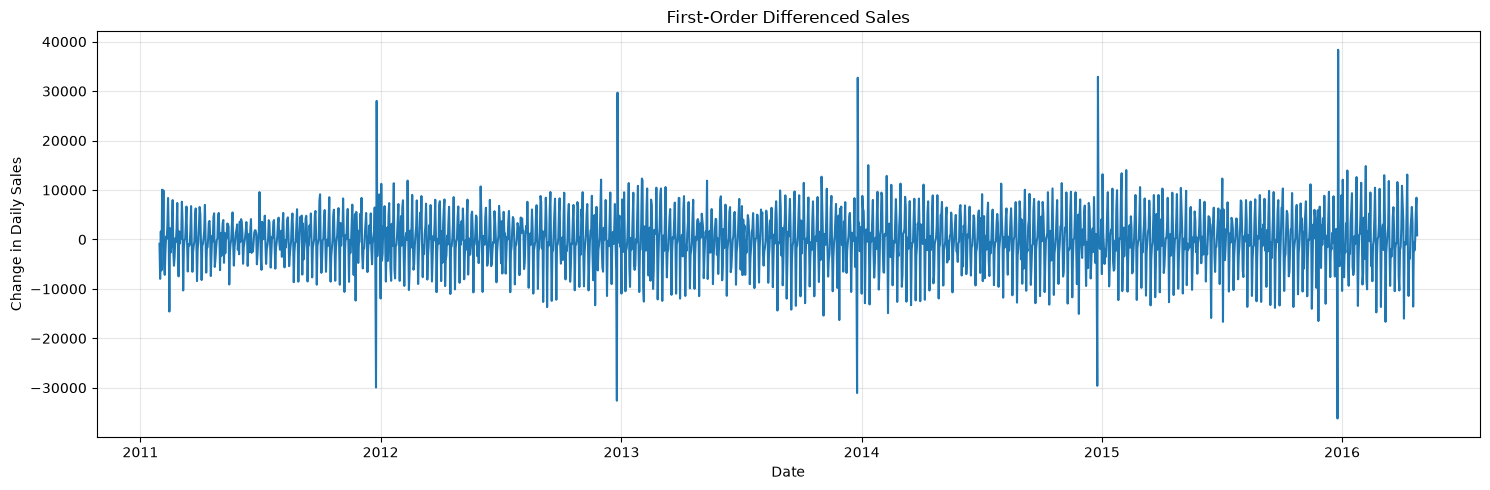

In [11]:
# First-order differencing
daily_ts["sales_diff"] = daily_ts["sales"].diff()

# Remove the first missing value
sales_diff = daily_ts["sales_diff"].dropna()

print("Differenced Series Summary:")
display(sales_diff.describe())

# Visualize differenced sales
plt.figure(figsize=(15, 5))

plt.plot(sales_diff)

plt.title("First-Order Differenced Sales")
plt.xlabel("Date")
plt.ylabel("Change in Daily Sales")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [12]:
adf_diff = adfuller(sales_diff)

print("ADF Statistic:", adf_diff[0])
print("p-value:", adf_diff[1])

if adf_diff[1] <= 0.05:
    print("Conclusion: Differenced series is Stationary.")
else:
    print("Conclusion: Differenced series is Non-Stationary.")

ADF Statistic: -23.459578820632576
p-value: 0.0
Conclusion: Differenced series is Stationary.


/tmp/ipykernel_34359/175836590.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_diff = adfuller(sales_diff)


### Observations: First-Order Differencing and ADF Test

1. The original sales series was non-stationary, with an ADF p-value of 0.5010.
2. First-order differencing was applied to remove the changing trend.
3. The differenced series has a mean of approximately 8.98 and a standard deviation of 5,927.56.
4. After differencing, the ADF statistic decreased to -23.4596.
5. The p-value became 0.0 (effectively smaller than the displayed precision of the output), which is below the 0.05 significance level.

**Conclusion:** We reject the null hypothesis and conclude that the first-order differenced sales series is stationary according to the ADF test. Therefore, one level of differencing (d = 1) is sufficient for this series under this test.

# 8. ACF Plot (Autocorrelation Function)
Now we'll study how current sales changes relate to their previous values.

In [13]:
from statsmodels.tsa.stattools import acf, pacf

In [14]:
acf_values = acf(sales_diff, nlags=40)
pacf_values = pacf(sales_diff, nlags=40, method="ywm")

print("ACF Values:")
print(np.round(acf_values[:15], 3))

print("\nPACF Values:")
print(np.round(pacf_values[:15], 3))

ACF Values:
[ 1.     0.06  -0.276 -0.264 -0.268 -0.259  0.192  0.648  0.201 -0.251
 -0.262 -0.285 -0.239  0.201  0.62 ]

PACF Values:
[ 1.     0.06  -0.281 -0.246 -0.375 -0.568 -0.435  0.169  0.191  0.035
  0.025 -0.05  -0.173 -0.189  0.105]


### Visualizing the above data

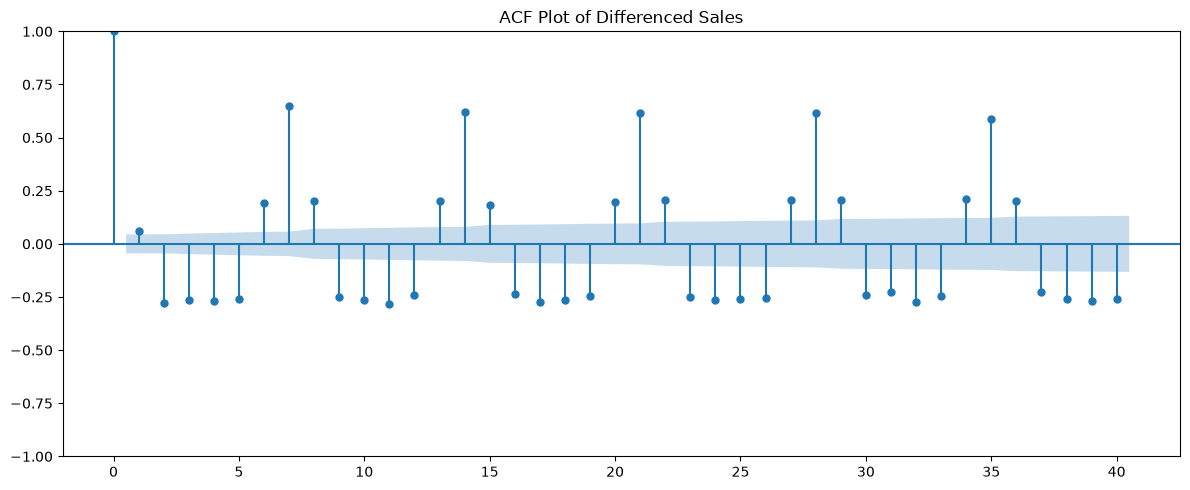

In [15]:
plt.figure(figsize=(12, 5))

plot_acf(
    sales_diff,
    lags=40,
    ax=plt.gca()
)

plt.title("ACF Plot of Differenced Sales")
plt.tight_layout()
plt.show()

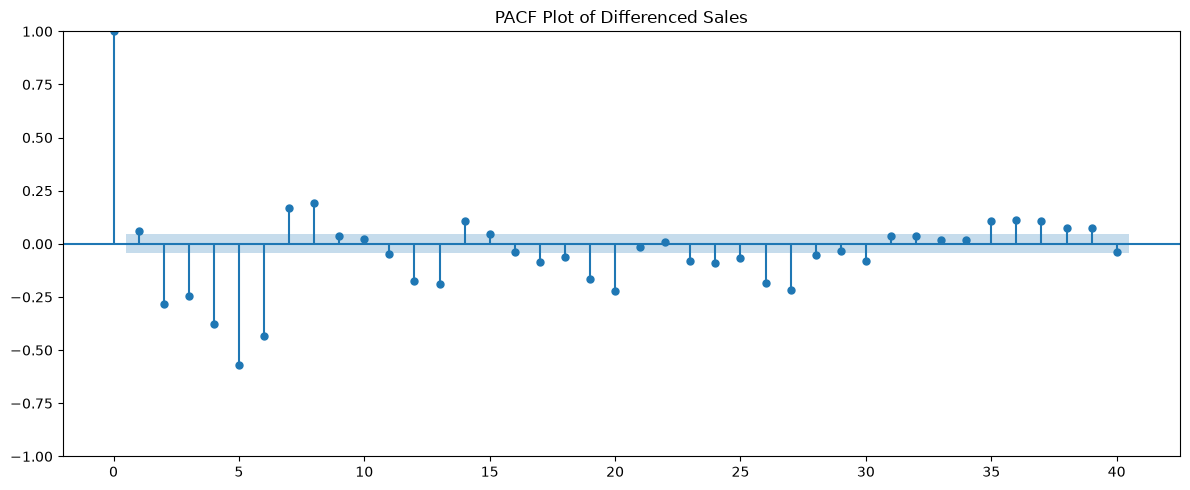

In [16]:
plt.figure(figsize=(12, 5))

plot_pacf(
    sales_diff,
    lags=40,
    ax=plt.gca(),
    method="ywm"
)

plt.title("PACF Plot of Differenced Sales")
plt.tight_layout()
plt.show()

ACF and PACF interpretation
1. ACF (Autocorrelation Function)
- Lag 1: 0.060 — very weak positive correlation.
- Lags 2–5: around -0.26 — negative correlation.
- Lag 7: 0.648 — strong positive correlation.
- Lag 14: 0.620 — another strong positive correlation.
Interpretation: The strong positive correlations at lags 7 and 14 suggest that a weekly pattern remains in the differenced sales data.

2. PACF (Partial Autocorrelation Function)
- Lag 1: 0.060 — weak direct correlation.
- Lags 2–6 show negative correlations, particularly lag 5 at -0.568.
- The later values are comparatively smaller, with some fluctuations.
Interpretation: The PACF suggests short-term relationships between sales changes and previous observations. The negative values indicate inverse relationships at those lags.

### Observations: ACF and PACF Analysis

1. The ACF plot shows a strong positive correlation at lags 7 and 14.
2. This indicates that weekly patterns remain in the differenced sales series.
3. The PACF plot shows notable negative correlations at lags 2–6, especially at lag 5.
4. These patterns suggest that past sales changes influence current sales changes.
5. The remaining weekly autocorrelation indicates that first-order differencing alone has not removed all seasonal patterns.

**Conclusion:** The ACF and PACF results reveal a strong weekly autocorrelation pattern. Seasonal components should therefore be considered while developing forecasting models.



# 9. Seasonal Differencing
Our ACF showed strong peaks at lag 7 and 14, suggesting a weekly pattern. So we'll check whether differencing with a 7-day lag helps.

What we're doing: Comparing each day's sales with sales from the same weekday in the previous week. 

Seasonally Differenced Series:


count     1906.000000
mean        50.019412
std       4499.294374
min     -34742.000000
25%      -2581.500000
50%       -559.500000
75%       2392.250000
max      32637.000000
Name: sales, dtype: float64

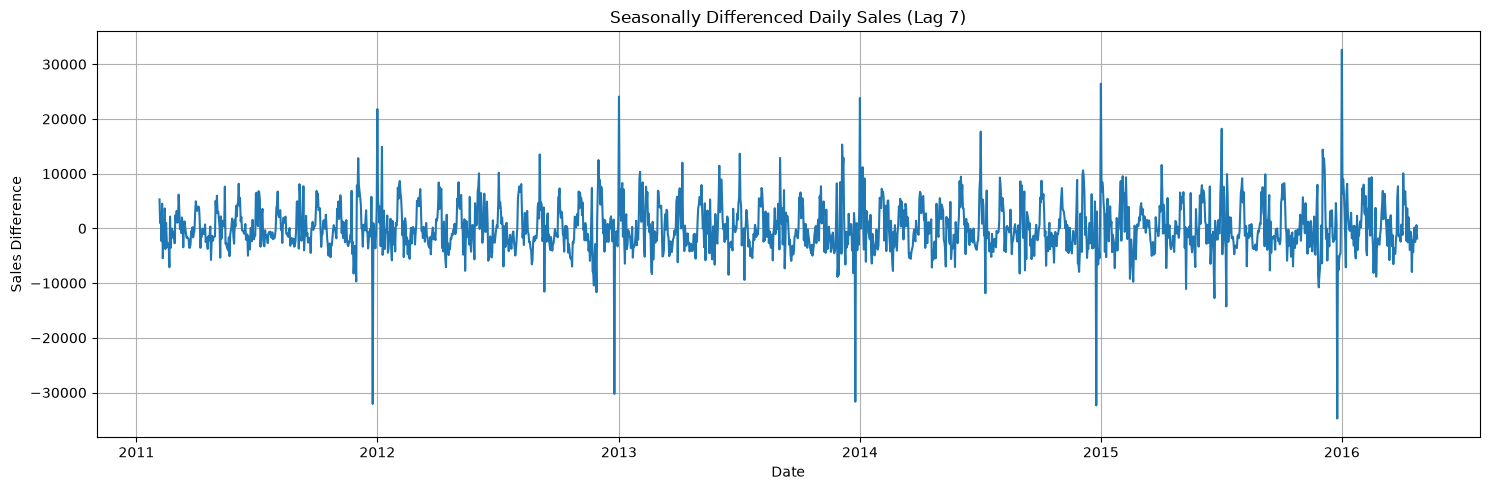

In [17]:
# Apply seasonal differencing with a lag of 7 days
sales_seasonal_diff = daily_ts["sales"].diff(7).dropna()

print("Seasonally Differenced Series:")
display(sales_seasonal_diff.describe())

# Visualize the result
plt.figure(figsize=(15, 5))
plt.plot(sales_seasonal_diff)
plt.title("Seasonally Differenced Daily Sales (Lag 7)")
plt.xlabel("Date")
plt.ylabel("Sales Difference")
plt.grid(True)
plt.tight_layout()
plt.show()

Quick interpretation
- Mean: 50.02 — very close to zero.
- Standard deviation: 4,499.29 — sales fluctuations remain.
- Minimum: -34,742.
- Maximum: 32,637.
- The differenced series still has considerable variation.
Important: A mean close to zero doesn't automatically mean the series is stationary. We'll verify that using the ADF test

# 10. ADF Test after Seasonal Differencing

In [18]:
adf_seasonal = adfuller(sales_seasonal_diff)

print("ADF Statistic:", adf_seasonal[0])
print("p-value:", adf_seasonal[1])

if adf_seasonal[1] <= 0.05:
    print("Conclusion: Seasonally differenced series is Stationary.")
else:
    print("Conclusion: Seasonally differenced series is Non-Stationary.")

ADF Statistic: -20.921898887606837
p-value: 0.0
Conclusion: Seasonally differenced series is Stationary.


/tmp/ipykernel_34359/567657334.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_seasonal = adfuller(sales_seasonal_diff)


Interpretation
Test	ADF Statistic	p-value	Result
Original sales	-1.565	0.501	Non-stationary
First difference (d=1)	-23.460	0.0	Stationary
Seasonal difference (D=1, lag 7)	-20.922	0.0	Stationary

What this tells us:
- Original sales data was non-stationary.
- First-order differencing made it stationary.
- Seasonal differencing with lag 7 also made it stationary.
- Both methods provide evidence of stationarity according to the ADF test.
### Observations: Seasonal Differencing and ADF Test

1. Seasonal differencing was applied with a lag of 7 to capture weekly patterns.
2. The resulting series has a mean of approximately 50.02.
3. The ADF statistic is -20.9219.
4. The p-value is 0.0, which is below the 0.05 significance level.
5. We reject the null hypothesis of non-stationarity.

**Conclusion:** Seasonal differencing with a 7-day lag produces a stationary series according to the ADF test. Both first-order and seasonal differencing achieve stationarity independently. Further model evaluation will help determine the appropriate differencing strategy.

# 11. Compare Differencing Methods

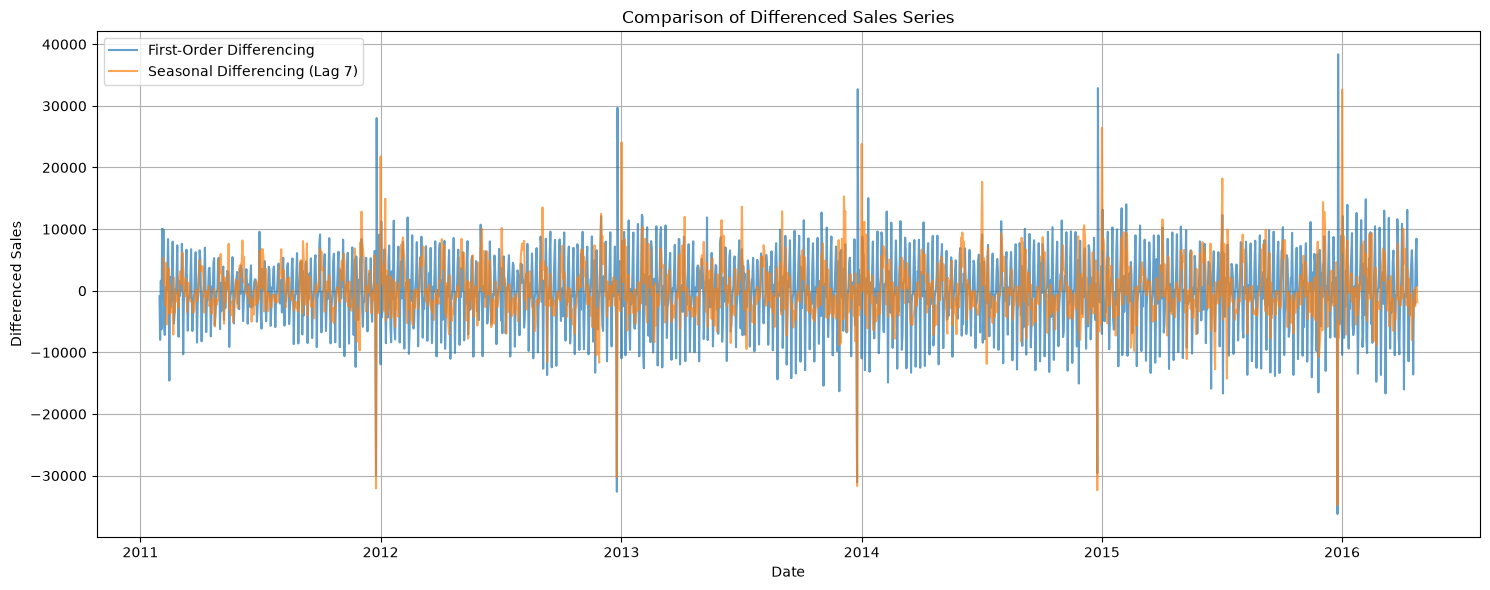

In [19]:
plt.figure(figsize=(15, 6))

plt.plot(
    sales_diff,
    label="First-Order Differencing",
    alpha=0.7
)

plt.plot(
    sales_seasonal_diff,
    label="Seasonal Differencing (Lag 7)",
    alpha=0.7
)

plt.title("Comparison of Differenced Sales Series")
plt.xlabel("Date")
plt.ylabel("Differenced Sales")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()